# Delivery Performance & Customer Satisfaction: analysis notebook

**Engagement question:** *How should the marketplace prioritise operational improvements to reduce delivery
delays and improve customer satisfaction?*

This notebook walks through the evidence chain behind the recommendations in `reports/executive_memo.md`.
It reads the outputs of the reproducible pipeline (`make pipeline`) and recomputes the key figures live.

| Section | Question |
|---|---|
| 1 | Is the data fit for purpose? |
| 2 | How big is the delivery problem, and is it worth solving? |
| 3 | Where do late deliveries originate? |
| 4 | Is the lateness-satisfaction link real, or a confounder? (correlation vs causation) |
| 5 | Can we fix it by changing the promise instead of the delivery? |
| 6 | What could the proposed interventions achieve? (scenario) |
| 7 | What we can and cannot conclude |

*Data: Olist Brazilian E-Commerce Public Dataset (Kaggle, CC BY-NC-SA 4.0). Analysis window: Jan 2017 - Aug 2018.*

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "python"))
from olist_ba.clean import load_processed
from olist_ba import kpis

OUT = ROOT / "outputs"
q = lambda n: pd.read_csv(OUT / "sql" / "analysis" / f"{n}.csv")
chart = lambda f: display(Image(filename=str(ROOT / "assets" / "charts" / f), width=820))
km = json.loads((OUT / "key_metrics.json").read_text())
orders = load_processed("order_summary")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
print(f"{len(orders):,} orders loaded | interpreter: {Path(sys.executable).parent.parent.name}/{Path(sys.executable).name}")

99,441 orders loaded | interpreter: .venv/python


## 1. Data fitness

Before analysing anything, the pipeline proves the data is complete and internally consistent:
row counts match from raw to modelled layer, keys are unique, every foreign key resolves, typed totals
reconcile to the cent, and an **independent pandas implementation** of all cleaning rules reproduces the SQL
view column-for-column (tested in `tests/test_reconciliation.py`).

In [2]:
checks = pd.concat([pd.read_csv(p).assign(suite=p.stem) for p in sorted((OUT / "sql" / "validation").glob("*.csv"))])
print(checks["status"].value_counts().to_string())
checks[checks["status"] == "INFO"][["suite", "check_name", "actual"]]

status
PASS    31
INFO     9


,suite,check_name,actual
1,v05_payment_vs_items,orders with payment > items by more than R$1,232.0
2,v05_payment_vs_items,orders with payment < items by more than R$1,17.0
1,v07_analysis_window,orders outside window (excluded from trend KPIs),349.0
0,v08_data_quality_flags,carrier handoff before payment approval,1359.0
1,v08_data_quality_flags,customer delivery before carrier handoff,23.0
2,v08_data_quality_flags,status/date conflict,14.0
3,v08_data_quality_flags,products with unknown category,610.0
4,v08_data_quality_flags,orders with more than one review (latest kept ...,547.0
5,v08_data_quality_flags,orders with no payment record,1.0


The `INFO` rows are known data-quality characteristics that are **kept and flagged**, not deleted
(see `docs/04_data_cleaning_log.md`). For example, 1,359 orders record a carrier handoff before payment approval;
they are excluded only from the stage-duration medians where that ordering matters.

## 2. Size of the problem

In [3]:
k = kpis.kpi_scorecard(orders)
pd.Series(k).to_frame("value")

,value
revenue_orders,9.791000e+04
product_revenue,1.344953e+07
freight_revenue,2.234177e+06
avg_order_value,1.373700e+02
items_per_order,1.141000e+00
unique_customers,9.470700e+04
freight_to_price_ratio,1.661000e-01
cancel_unavailable_rate,1.190000e-02
on_time_delivery_rate,9.321000e-01
avg_delivery_days,1.254000e+01


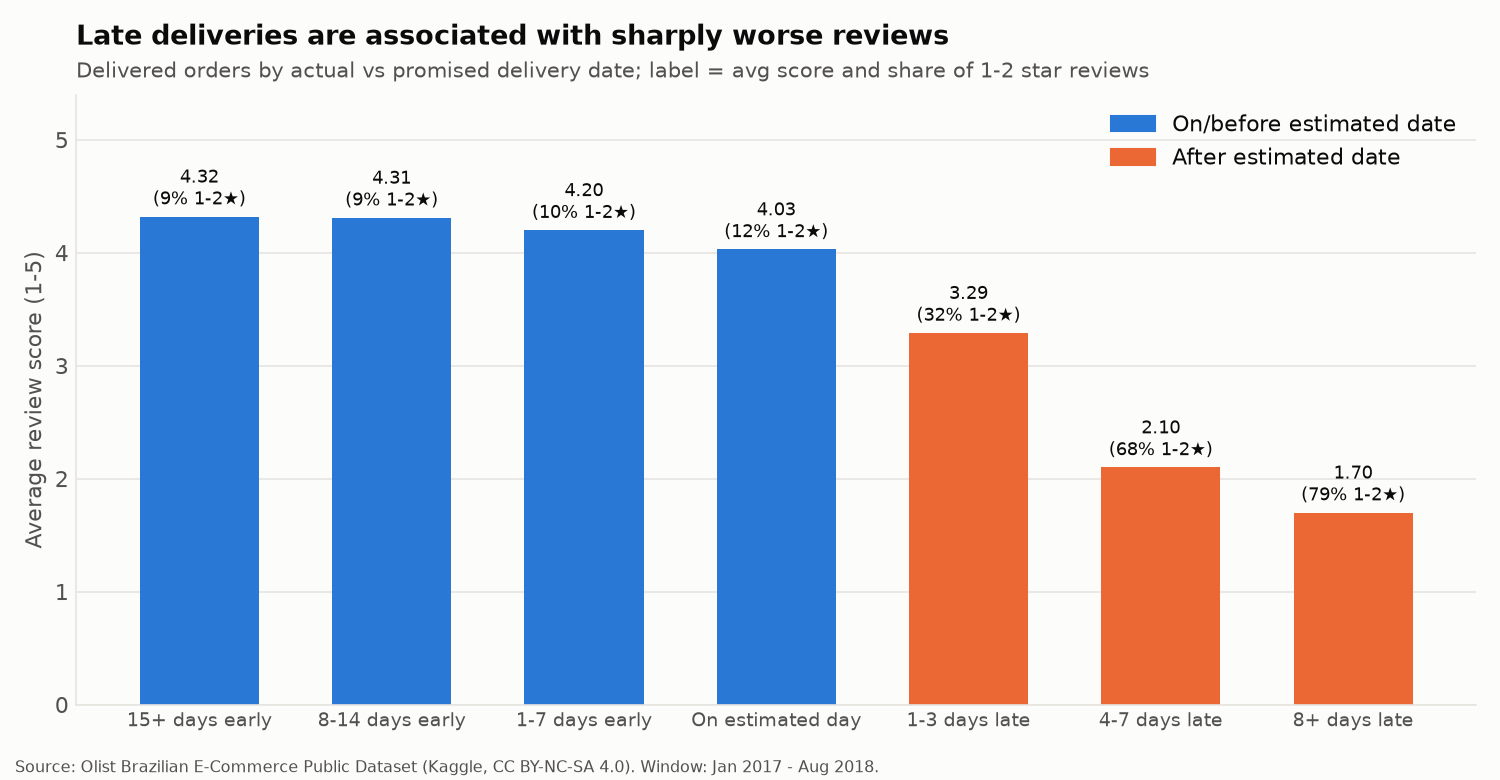

In [4]:
chart('04_delivery_vs_review.png')

About 7% of delivered orders arrive after the date promised at checkout. That sounds small, but the review
distribution changes sharply once an order is late: on-time orders average above 4 stars, orders 8+ days late
average 1.7. Because 97% of customers buy only once in the window, reviews are the platform's main public
reputation signal for new buyers. That makes them, rather than repeat purchases, the main reason lateness matters.

## 3. Where late deliveries originate

In [5]:
dec = pd.read_csv(OUT / "root_cause" / "late_decomposition.csv")
dec

,origin,Other 17 months,"Peak months (Nov-17, Feb-18, Mar-18)",Total,Other 17 months (share),"Peak months (Nov-17, Feb-18, Mar-18) (share)",Total (share)
0,Seller missed shipping limit,1103,706,1809,0.1692,0.1083,0.2775
1,Seller on time -> delay after carrier handoff,2264,2445,4709,0.3473,0.3751,0.7225
2,Total,3367,3151,6518,0.5166,0.4834,1.0000


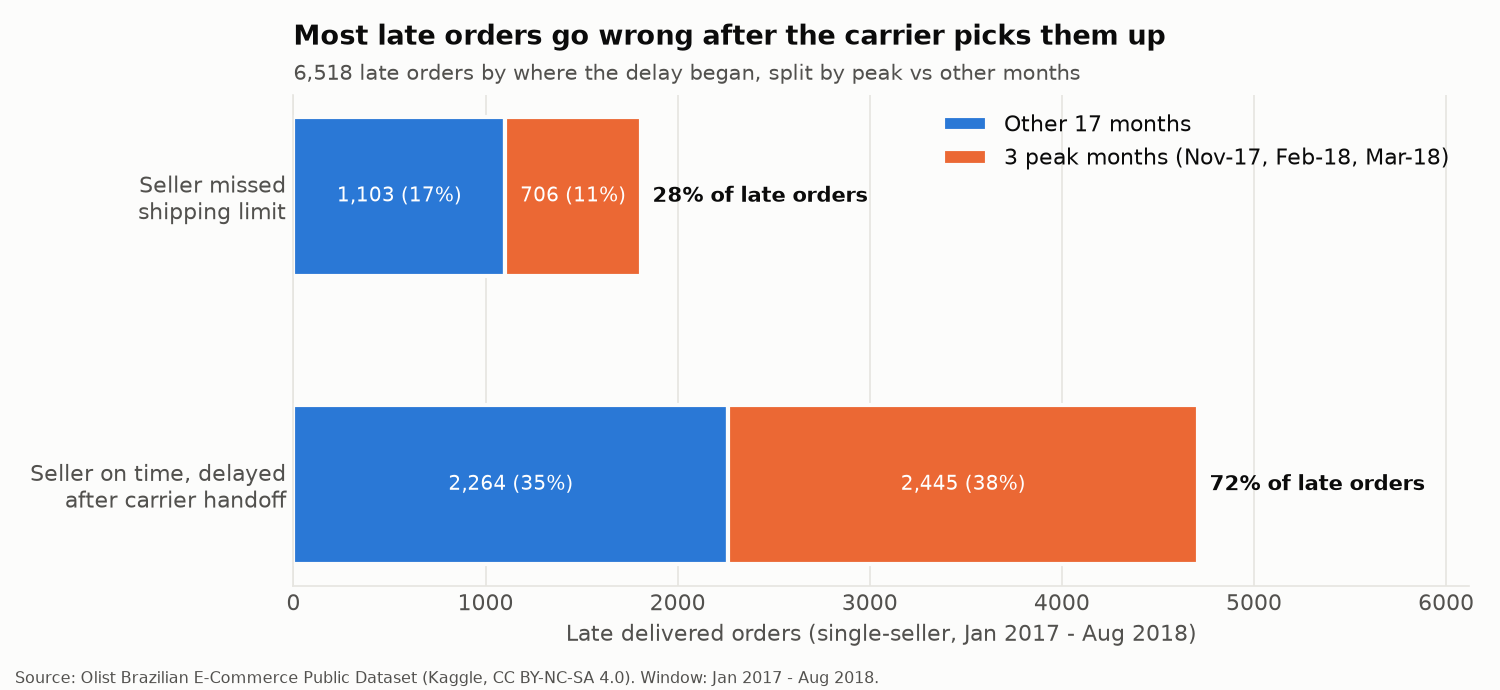

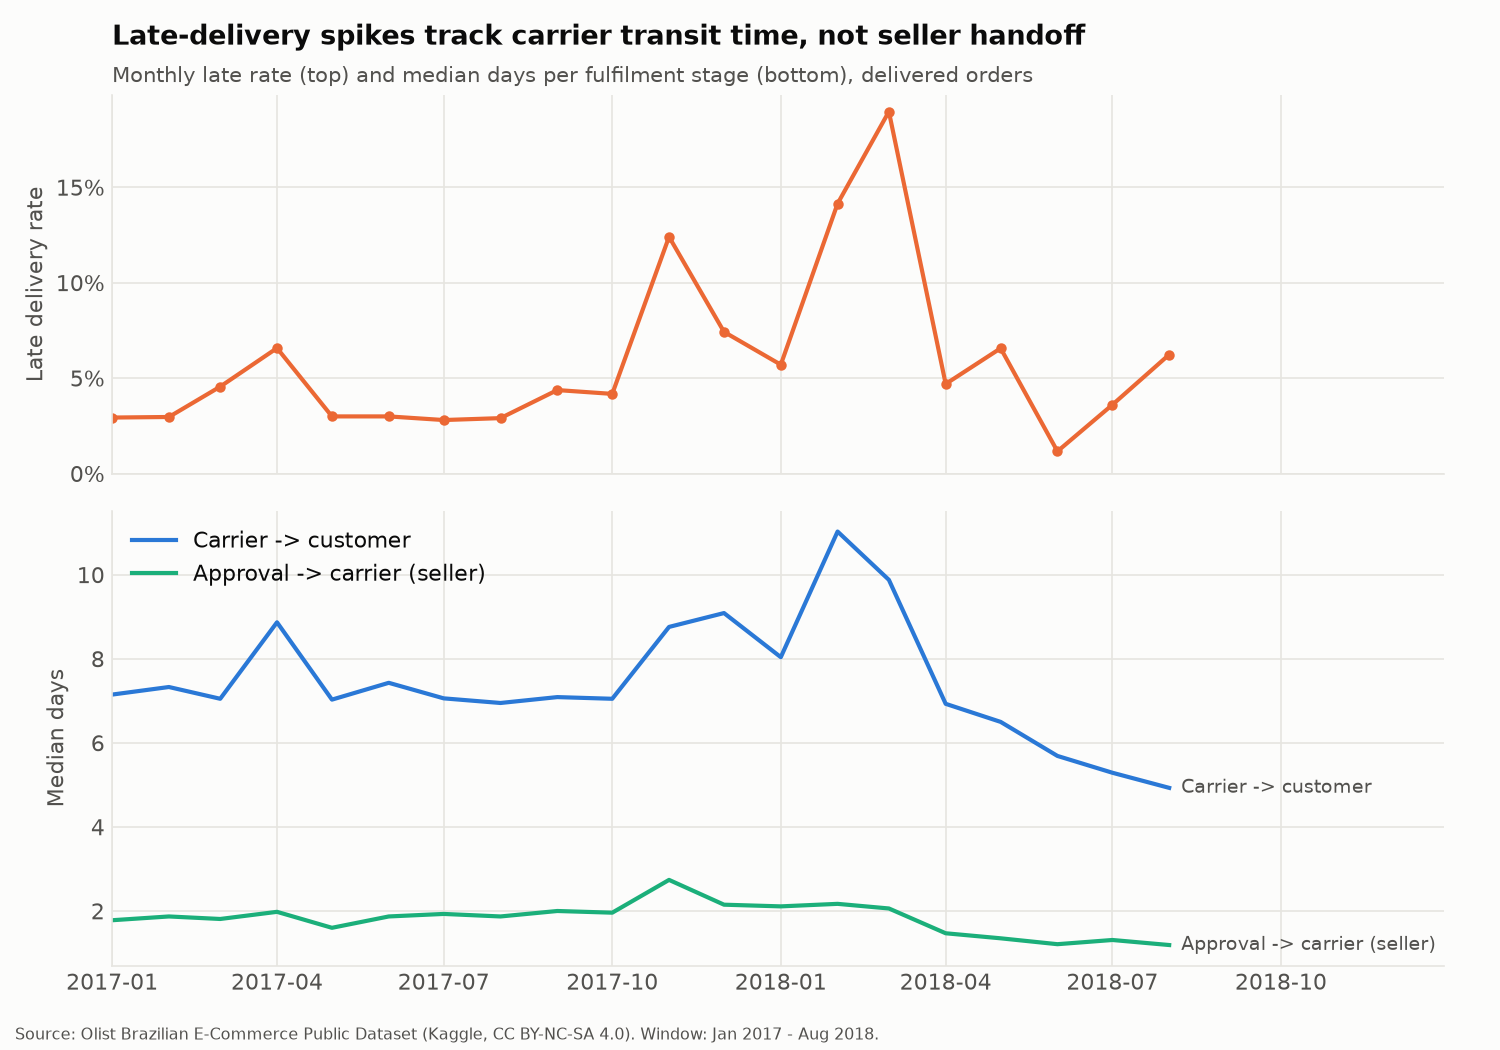

In [6]:
chart('13_late_order_origin.png'); chart('05_fulfilment_stage_trend.png')

In [7]:
lanes = pd.read_csv(OUT / "root_cause" / "top_routes_excess_late.csv")
print(f"Top 15 lanes: {km['top15_lanes_share_of_excess_late']:.0%} of excess late orders "
      f"on {km['top15_lanes_share_of_volume']:.0%} of delivered volume")
lanes.head(10)

Top 15 lanes: 88% of excess late orders on 22% of delivered volume


,route,delivered,late,median_days,avg_promised_days,low_review_rate,late_rate,excess_late
0,SP->RJ,8031,1147.0,12.8713,26.9564,0.1976,0.1428,595.5884
1,SP->BA,2275,297.0,17.7229,30.4374,0.1779,0.1305,140.7976
2,SP->ES,1443,180.0,13.6381,25.2328,0.1435,0.1247,80.9230
3,SP->CE,958,133.0,18.3675,31.8747,0.1668,0.1388,67.2233
4,SP->SC,2300,222.0,13.8753,26.6696,0.1461,0.0965,64.0811
5,SP->MA,483,93.0,19.4693,31.0600,0.2208,0.1925,59.8370
6,PR->RJ,948,117.0,14.1632,30.2131,0.1947,0.1234,51.9099
7,SP->AL,254,61.0,23.1425,32.8898,0.2421,0.2402,43.5603
8,SP->PA,672,81.0,20.9040,37.1443,0.1765,0.1205,34.8602
9,SP->PE,1122,111.0,15.9747,32.3583,0.1523,0.0989,33.9630


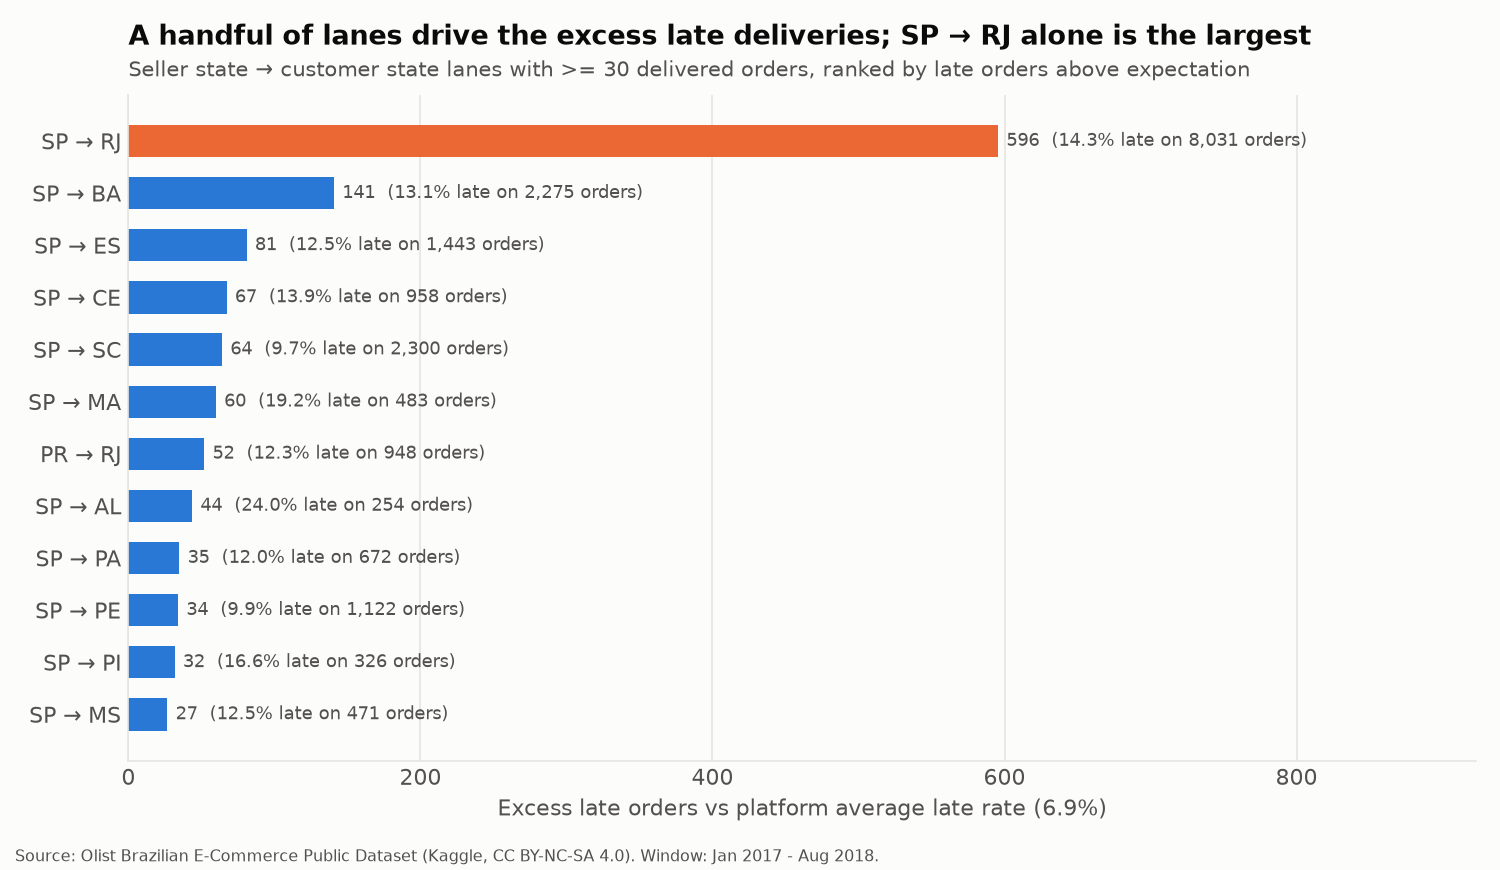

In [8]:
chart('14_lane_excess_late.png')

**Reading:** most late orders are not caused by sellers shipping late. The seller hands over on time and the
delay accrues afterwards, in transit. The problem is also concentrated in time (three peak months) and in
space (a few lanes out of São Paulo, led by SP → RJ). Seller SLA misses are a smaller but separate driver:
an order whose seller misses the shipping limit is ~4x as likely to arrive late.

*Limitation:* the dataset does not identify the carrier, so "post-handoff delay" cannot be split between
carrier performance, regional infrastructure and the 2018 events that may explain the Feb-Mar spike. That split
is a data request in the requirements document, not something this analysis can claim.

## 4. Correlation vs causation: is the satisfaction gap real?

A raw comparison could be confounded: a poor seller might ship slowly *and* sell poor products, which would
produce bad reviews regardless of lateness. Three increasingly strict comparisons:

In [9]:
rc = json.loads((OUT / "root_cause" / "root_cause_summary.json").read_text())["controlled_review_effect"]
pd.DataFrame({
    "method": ["Raw difference", "Within the same seller", "Logistic regression with controls (avg marginal effect)"],
    "gap in 1-2 star rate (pp)": [rc["raw_gap_pp"], rc["within_seller_gap_pp"], rc["logit_avg_marginal_effect_pp"]],
    "controls for": ["nothing", "everything stable about the seller", "price, freight, basket, interstate, state, category, month"],
})

,method,gap in 1-2 star rate (pp),controls for
0,Raw difference,53.7,nothing
1,Within the same seller,52.9,everything stable about the seller
2,Logistic regression with controls (avg margina...,51.1,"price, freight, basket, interstate, state, cat..."


In [10]:
pd.Series(rc['dose_response_low_review_by_days_late'], name='1-2 star rate by days late')

(0, 3]        0.3203
(3, 7]        0.6762
(7, 14]       0.8015
(14, 1000]    0.7832
Name: 1-2 star rate by days late, dtype: float64

The gap barely moves under controls (about 54 → 53 → 51 pp) and rises with the number of days late (a dose-response
pattern). The review is written after delivery, so reverse causation is implausible. This is **strong
observational evidence**, but it is still not proof: unobserved order-level factors such as transit damage
could travel with lateness. The memo therefore recommends a **controlled pilot** on target lanes before scaling.

## 5. Can we just change the promise?

In [11]:
pd.read_csv(OUT / 'root_cause' / 'estimate_backtest.csv').iloc[[0, 1, 11, 14, 16, 18]]

,policy,quantile,late_rate,avg_promised_days,median_promised_days,is_matched_to_current_avg_promise,test_orders
0,Current platform estimate,NaN,0.0783,23.4,23.0,False,51983
1,Route-calibrated P80,0.80,0.1843,16.4,16.0,False,51983
11,Route-calibrated P90,0.90,0.1026,20.7,19.0,False,51983
14,Route-calibrated P93,0.93,0.0745,23.2,21.0,True,51983
16,Route-calibrated P95,0.95,0.0547,25.6,23.0,False,51983
18,Route-calibrated P97,0.97,0.0347,29.5,27.0,False,51983


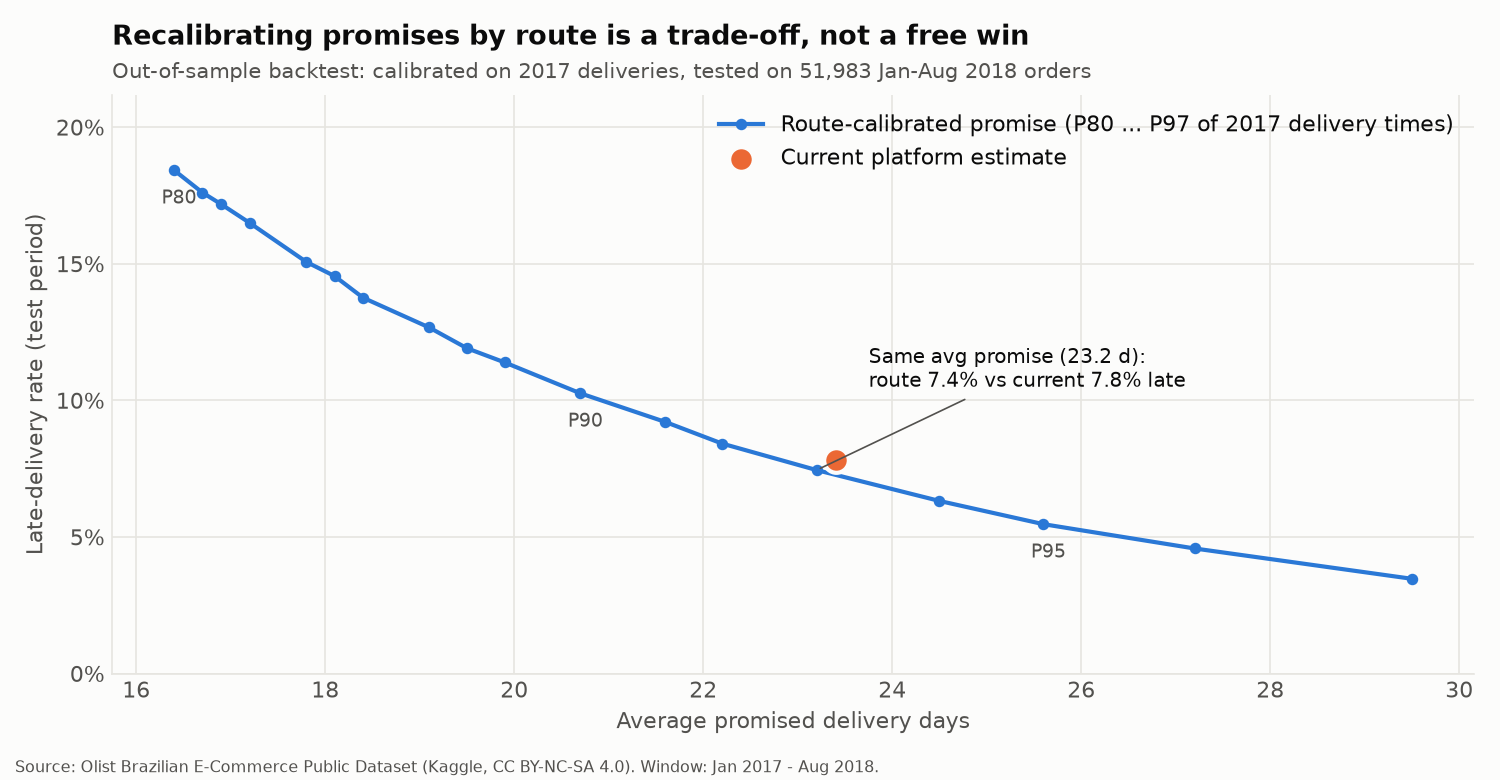

In [12]:
chart('16_promise_backtest.png')

An out-of-sample backtest (calibrate on 2017, test on 2018) shows route-level promises sit on the **same
trade-off curve** as the current estimate. At an equal average promise the late rate improves by under half a
point. Re-setting promises is therefore a low-value lever. The physical delivery has to improve.

## 6. Scenario: what could the interventions achieve?

In [13]:
sc = pd.read_csv(OUT / "scenarios" / "scenario_results.csv")
sc.pivot(index="lever", columns="case", values="new_late_rate")

case,base,high,low
lever,,,
"Combined (L1+L2+L4, overlap removed)",0.0534,0.0429,0.0640
L1,0.0702,0.0659,0.0744
L2,0.0707,0.0667,0.0747
L4,0.0670,0.0611,0.0713


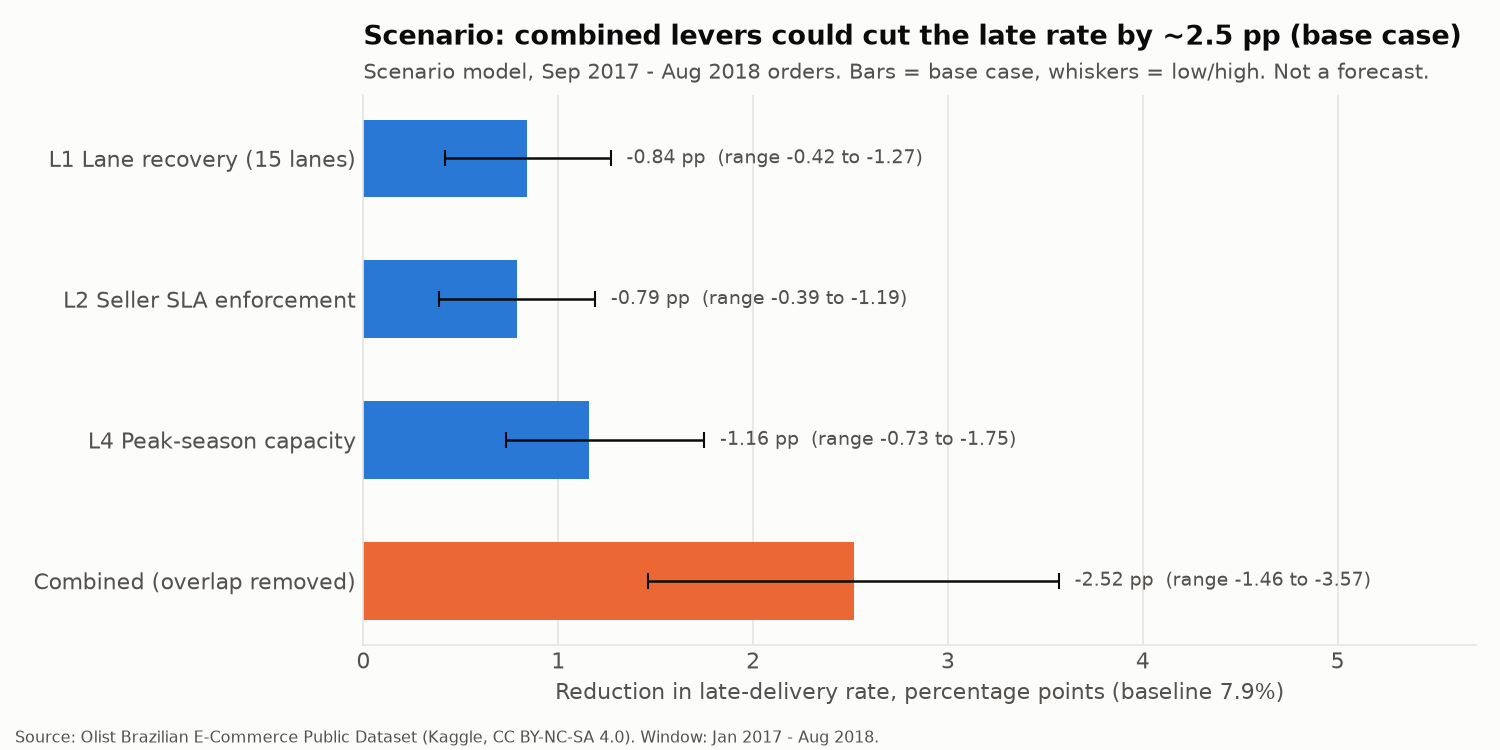

In [14]:
chart('15_scenario_impact.png')

Assumptions are listed in `docs/08_scenario_analysis.md` and are adjustable in the dashboard's scenario page.
Each lever acts only on the *excess* late rate of its segment, and overlaps are removed. Under base
assumptions, the late rate falls from about 7.9% to about 5.3% for the baseline year. That **misses a 5% target**,
which is why the charter sets a staged target and why the pilot's measured effect should replace these
assumptions.

## 7. What we can and cannot conclude

| Conclusion | Evidence grade |
|---|---|
| Late deliveries are concentrated in post-handoff transit, peak months and a few lanes | **Observed** (descriptive, complete data) |
| Late delivery is associated with a ~51-54 pp higher 1-2 star rate, robust to controls | **Strong association** (not proven causal) |
| Seller SLA misses are associated with a ~4x higher late rate | **Association** (seller confounding possible) |
| Lane interventions would reduce late deliveries | **Hypothesis**: test with a pilot |
| Revenue / retention impact of fixing lateness | **Not quantified.** The repeat-purchase effect is statistically significant but small in absolute terms, and the data contains no cost or margin. |

In [15]:
print(f"Repeat rate after a late first order: {km['repeat_rate_first_late']:.2%} vs on time {km['repeat_rate_first_on_time']:.2%} "
      f"(p = {km['repeat_p_value']:.4f})")

Repeat rate after a late first order: 2.74% vs on time 3.55% (p = 0.0016)
